## 1. Import Dataset dan Library 
Mengimport library yang dibutuhkan kemudian mengimport dataset yang sudah didownload menggunakan pd.read_excel. Setelah itu melakukan sedikit explorasi data dengan menampilkan head, info, shape.

In [24]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

In [4]:
df = pd.read_excel('Online Retail.xlsx')
display(df.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
print('Shape:', df.shape)
print()
df.info()

Shape: (541909, 8)

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## 2. Eksplorasi dan Pembersihan Data

**Kolom yang relevan.** Association Rule membutuhkan dua informasi: identitas transaksi dan item di dalamnya.
- `InvoiceNo` → identitas transaksi (satu invoice = satu keranjang belanja)
- `Description` → nama produk (item)
- `Quantity` → dipakai hanya untuk menyaring baris tidak valid

Kolom lain (`StockCode`, `InvoiceDate`, `UnitPrice`, `CustomerID`, `Country`) tidak diperlukan untuk pembentukan aturan.

Pada tahap ini dilakukan pembersihan data pada kolom-kolom yang relevan, kemudian dilihat item-item yang terlaris serta distribusi keranjang.

In [6]:
print('Nilai kosong per kolom:')
print(df.isna().sum())
print()
print('Jumlah invoice unik :', df['InvoiceNo'].nunique())
print('Jumlah produk unik  :', df['Description'].nunique())
print('Invoice dibatalkan  :', df['InvoiceNo'].astype(str).str.startswith('C').sum(), 'baris')
print('Quantity <= 0       :', (df['Quantity'] <= 0).sum(), 'baris')
print()
display(df[['Quantity', 'UnitPrice']].describe().round(2))

Nilai kosong per kolom:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Jumlah invoice unik : 25900
Jumlah produk unik  : 4223
Invoice dibatalkan  : 9288 baris
Quantity <= 0       : 10624 baris



,Quantity,UnitPrice
count,541909.00,541909.00
mean,9.55,4.61
std,218.08,96.76
min,-80995.00,-11062.06
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,80995.00,38970.00


In [ ]:
log = []
def catat(tahap, d):
    log.append({'Tahap': tahap, 'Jumlah baris': len(d), 'Jumlah invoice': d['InvoiceNo'].nunique()})

data = df.copy()
data['InvoiceNo'] = data['InvoiceNo'].astype(str)
catat('Data awal', data)

# Hapus baris yang memiliki Description kosong
data['Description'] = data['Description'].astype('object').str.strip()
data = data[data['Description'].notna() & (data['Description'] != '')]
catat('Hapus Description kosong', data)

# Hapus invoice dibatalkan (C)  
data = data[~data['InvoiceNo'].str.startswith('C')]
catat('Hapus invoice dibatalkan (C)', data)

# Hapus baris dengan Quantity <= 0
data = data[data['Quantity'] > 0]
catat('Hapus Quantity <= 0', data)

ringkasan = pd.DataFrame(log)
ringkasan['Baris terhapus'] = (-ringkasan['Jumlah baris'].diff()).fillna(0).astype(int)
ringkasan['Invoice terhapus'] = (-ringkasan['Jumlah invoice'].diff()).fillna(0).astype(int)
display(ringkasan)

print(f"Sebelum : {len(df):,} baris | {df['InvoiceNo'].nunique():,} invoice")
print(f"Sesudah : {len(data):,} baris | {data['InvoiceNo'].nunique():,} invoice | {data['Description'].nunique():,} produk unik")

,Tahap,Jumlah baris,Jumlah invoice,Baris terhapus,Invoice terhapus
0,Data awal,541909,25900,0,0
1,Hapus Description kosong,540454,24445,1455,1455
2,Hapus invoice dibatalkan (C),531166,20609,9288,3836
3,Hapus Quantity <= 0,530693,20136,473,473


Sebelum : 541,909 baris | 25,900 invoice
Sesudah : 530,693 baris | 20,136 invoice | 4,065 produk unik


**Eksplorasi singkat setelah pembersihan:** melihat produk terlaris dan distribusi ukuran keranjang.

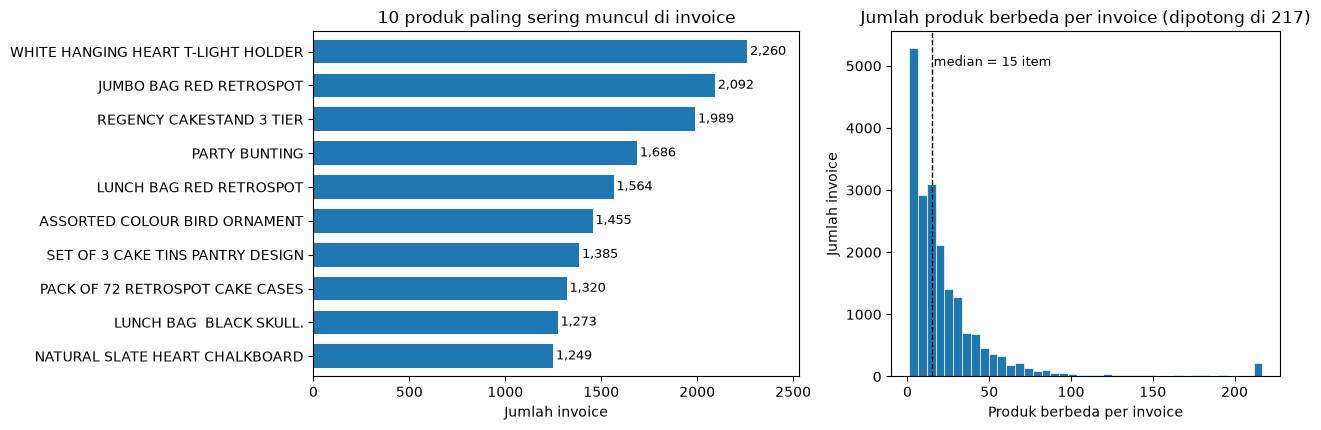

Rata-rata item/invoice: 25.8 | median: 15 | maks: 1108


In [10]:
top10 = data.groupby('Description')['InvoiceNo'].nunique().sort_values(ascending=False).head(10)
ukuran = data.groupby('InvoiceNo')['Description'].nunique()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={'width_ratios': [1.25, 1]})

top10[::-1].plot.barh(ax=ax[0], width=0.7)
ax[0].set_title('10 produk paling sering muncul di invoice')
ax[0].set_xlabel('Jumlah invoice'); ax[0].set_ylabel('')
for i, v in enumerate(top10[::-1]):
    ax[0].text(v + 15, i, f'{v:,}', va='center', fontsize=9)
ax[0].set_xlim(0, top10.max() * 1.12)

batas = int(ukuran.quantile(0.99))
ax[1].hist(ukuran.clip(upper=batas), bins=40, edgecolor='white', linewidth=0.5)
ax[1].axvline(ukuran.median(), color='black', linestyle='--', linewidth=1)
ax[1].text(ukuran.median() + 1, ax[1].get_ylim()[1] * 0.9, f'median = {ukuran.median():.0f} item', fontsize=9)
ax[1].set_title(f'Jumlah produk berbeda per invoice (dipotong di {batas})')
ax[1].set_xlabel('Produk berbeda per invoice'); ax[1].set_ylabel('Jumlah invoice')
plt.tight_layout(); plt.show()

print(f'Rata-rata item/invoice: {ukuran.mean():.1f} | median: {ukuran.median():.0f} | maks: {ukuran.max()}')

## 3. Persiapan Data untuk Association Rule

Setiap invoice diubah menjadi satu transaksi berisi daftar produk unik, lalu dikodekan ke bentuk one-hot dengan `TransactionEncoder` dari mlxtend.

In [ ]:
transaksi = (data.groupby('InvoiceNo')['Description']
                 .apply(lambda s: sorted(set(s)))
                 .rename('Daftar produk'))
print('Jumlah transaksi:', len(transaksi))
display(transaksi.head(5).to_frame())

Jumlah transaksi: 20136


,Daftar produk
InvoiceNo,
536365,"[CREAM CUPID HEARTS COAT HANGER, GLASS STAR FR..."
536366,"[HAND WARMER RED POLKA DOT, HAND WARMER UNION ..."
536367,"[ASSORTED COLOUR BIRD ORNAMENT, BOX OF 6 ASSOR..."
536368,"[BLUE COAT RACK PARIS FASHION, JAM MAKING SET ..."
536369,[BATH BUILDING BLOCK WORD]


In [12]:
te = TransactionEncoder()
matriks = te.fit(transaksi.tolist()).transform(transaksi.tolist(), sparse=False)
basket = pd.DataFrame(matriks, columns=te.columns_, index=transaksi.index)

print('Ukuran basket one-hot (transaksi x produk):', basket.shape)
print('Kepadatan matriks (proporsi True):', round(basket.values.mean(), 5))
display(basket.iloc[:5, :6])

Ukuran basket one-hot (transaksi x produk): (20136, 4065)
Kepadatan matriks (proporsi True): 0.00635


,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD
InvoiceNo,,,,,,
536365,False,False,False,False,False,False
536366,False,False,False,False,False,False
536367,False,False,False,False,False,False
536368,False,False,False,False,False,False
536369,False,False,False,False,False,False


## 4. Penerapan Algoritma
Algoritma **Apriori** dengan titik awal `min_support = 0.01` dan `min_confidence = 0.5`, sesuai ketentuan praktikum.

In [ ]:
MIN_SUPPORT, MIN_CONF = 0.01, 0.5

item_umum = basket.columns[basket.mean() >= MIN_SUPPORT]
print(f'Produk dengan support >= {MIN_SUPPORT}: {len(item_umum)} dari {basket.shape[1]}')

t0 = time.time()
frequent = apriori(basket[item_umum], min_support=MIN_SUPPORT, use_colnames=True, low_memory=True)
print(f'Apriori selesai dalam {time.time()-t0:.1f} detik')
frequent['panjang'] = frequent['itemsets'].apply(len)
print('Jumlah frequent itemset:', len(frequent))
display(frequent['panjang'].value_counts().sort_index().rename('Jumlah itemset').to_frame().rename_axis('Panjang itemset'))

Produk dengan support >= 0.01: 803 dari 4065
Apriori selesai dalam 1.6 detik
Jumlah frequent itemset: 1853


,Jumlah itemset
Panjang itemset,
1,803
2,818
3,215
4,16
5,1


In [15]:
rules = association_rules(frequent, metric='confidence', min_threshold=MIN_CONF)
rules['itemset'] = [frozenset(a | c) for a, c in zip(rules['antecedents'], rules['consequents'])]
rules['Jika membeli'] = rules['antecedents'].apply(lambda s: ' + '.join(sorted(s)))
rules['Maka juga membeli'] = rules['consequents'].apply(lambda s: ' + '.join(sorted(s)))
print('Jumlah aturan asosiasi (support >= 0.01, confidence >= 0.5):', len(rules))
display(rules[['support', 'confidence', 'lift']].describe().round(3))
print('Aturan dengan lift > 1:', f"{(rules['lift'] > 1).mean():.0%}")

Jumlah aturan asosiasi (support >= 0.01, confidence >= 0.5): 841


,support,confidence,lift
count,841.000,841.000,841.000
mean,0.014,0.650,17.528
std,0.004,0.110,13.856
min,0.010,0.500,4.819
25%,0.011,0.557,9.442
50%,0.012,0.627,12.663
75%,0.014,0.729,18.903
max,0.041,0.959,80.220


Aturan dengan lift > 1: 100%


## 5. Evaluasi Aturan Asosiasi

Metrik yang dipakai:
- **Support** = proporsi transaksi yang memuat seluruh item aturan (seberapa umum).
- **Confidence** = P(konsekuen | antecedent), peluang membeli konsekuen jika antecedent sudah dibeli.
- **Lift** = confidence / support konsekuen. Lift > 1 berarti item saling terkait lebih kuat daripada kebetulan.

In [ ]:
kolom = ['Jika membeli', 'Maka juga membeli', 'support', 'confidence', 'lift']
urut = (rules.assign(lift_r=rules['lift'].round(6))
             .sort_values(['lift_r', 'confidence'], ascending=False, kind='mergesort'))
print('10 aturan dengan lift tertinggi (apa adanya):')
display(urut.head(10)[kolom].round(3).reset_index(drop=True))

10 aturan dengan lift tertinggi (apa adanya):


,Jika membeli,Maka juga membeli,support,confidence,lift
0,HERB MARKER PARSLEY + HERB MARKER ROSEMARY,HERB MARKER THYME,0.010,0.944,80.220
1,HERB MARKER THYME,HERB MARKER PARSLEY + HERB MARKER ROSEMARY,0.010,0.857,80.220
2,HERB MARKER PARSLEY + HERB MARKER THYME,HERB MARKER ROSEMARY,0.010,0.953,79.961
3,HERB MARKER ROSEMARY,HERB MARKER PARSLEY + HERB MARKER THYME,0.010,0.846,79.961
4,HERB MARKER THYME,HERB MARKER ROSEMARY,0.011,0.932,78.236
5,HERB MARKER ROSEMARY,HERB MARKER THYME,0.011,0.921,78.236
6,HERB MARKER ROSEMARY + HERB MARKER THYME,HERB MARKER PARSLEY,0.010,0.919,77.714
7,HERB MARKER PARSLEY,HERB MARKER ROSEMARY + HERB MARKER THYME,0.010,0.853,77.714
8,HERB MARKER THYME,HERB MARKER PARSLEY,0.011,0.899,76.037
9,HERB MARKER PARSLEY,HERB MARKER THYME,0.011,0.895,76.037


In [23]:
unik = urut.drop_duplicates('itemset').copy()
unik['keluarga'] = unik['itemset'].apply(lambda s: ' '.join(sorted(s)[0].split()[:2]))

terpilih, dipakai = [], set()
for _, r in unik.iterrows():
    if r['keluarga'] not in dipakai:
        terpilih.append(r); dipakai.add(r['keluarga'])
    if len(terpilih) == 3:
        break
top3 = pd.DataFrame(terpilih)

print(f"Itemset unik pada aturan: {len(unik)} dari {len(rules)} aturan")
print('Tiga aturan terbaik berdasarkan lift (keluarga produk berbeda):')
display(top3[kolom].round(3).reset_index(drop=True))

Itemset unik pada aturan: 423 dari 841 aturan
Tiga aturan terbaik berdasarkan lift (keluarga produk berbeda):


,Jika membeli,Maka juga membeli,support,confidence,lift
0,HERB MARKER PARSLEY + HERB MARKER ROSEMARY,HERB MARKER THYME,0.010,0.944,80.220
1,REGENCY TEA PLATE PINK,REGENCY TEA PLATE GREEN + REGENCY TEA PLATE ROSES,0.013,0.836,52.774
2,SET OF 3 WOODEN TREE DECORATIONS,SET OF 3 WOODEN STOCKING DECORATION,0.011,0.747,47.180


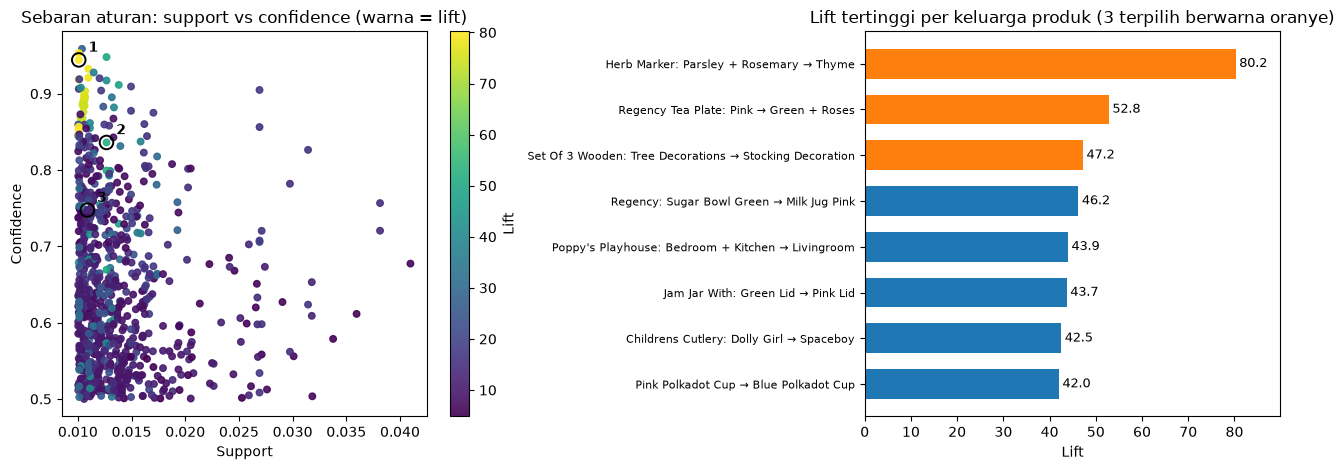

In [21]:
import textwrap, string

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1.1, 1]})

# Kiri: sebaran support vs confidence, warna = lift
sc = ax[0].scatter(rules['support'], rules['confidence'], c=rules['lift'], s=22, alpha=0.9)
cb = plt.colorbar(sc, ax=ax[0]); cb.set_label('Lift')
ax[0].scatter(top3['support'], top3['confidence'], s=95, facecolor='none', edgecolor='black', linewidth=1.4, zorder=5)
for i, (_, r) in enumerate(top3.iterrows(), 1):
    ax[0].annotate(f'{i}', (r['support'], r['confidence']), xytext=(7, 6), textcoords='offset points',
                   fontsize=10, fontweight='bold')
ax[0].set_title('Sebaran aturan: support vs confidence (warna = lift)')
ax[0].set_xlabel('Support'); ax[0].set_ylabel('Confidence')

# Kanan: lift tertinggi per keluarga produk
def ringkas(a, c):
    # Bagian awal nama yang sama pada semua item ditulis sekali sebagai awalan
    item = sorted(a) + sorted(c)
    kata = [x.split() for x in item]
    n = 0
    while all(len(k) > n + 1 for k in kata) and len({k[n] for k in kata}) == 1:
        n += 1
    sa = string.capwords(' + '.join(' '.join(x.split()[n:]) for x in sorted(a)).lower())
    sc_ = string.capwords(' + '.join(' '.join(x.split()[n:]) for x in sorted(c)).lower())
    awalan = (string.capwords(' '.join(kata[0][:n]).lower()) + ': ') if n else ''
    return textwrap.shorten(f'{awalan}{sa} → {sc_}', width=70, placeholder='…')

per_keluarga = unik.drop_duplicates('keluarga').head(8).iloc[::-1].reset_index(drop=True)
label = [ringkas(r.antecedents, r.consequents) for r in per_keluarga.itertuples()]
warna = ['C1' if i >= len(per_keluarga) - 3 else 'C0' for i in range(len(per_keluarga))]
ax[1].barh(label, per_keluarga['lift'], color=warna, height=0.65)
for y, v in enumerate(per_keluarga['lift']):
    ax[1].text(v + 0.8, y, f'{v:.1f}', va='center', fontsize=9)
ax[1].set_xlim(0, per_keluarga['lift'].max() * 1.12)
ax[1].set_title('Lift tertinggi per keluarga produk (3 terpilih berwarna oranye)')
ax[1].set_xlabel('Lift')
ax[1].tick_params(axis='y', labelsize=8)

plt.tight_layout(); plt.show()

### Interpretasi tiga aturan terbaik

| # | Aturan (jika membeli → juga membeli) | Support | Confidence | Lift |
|---|---|---|---|---|
| 1 | Herb Marker Parsley + Herb Marker Rosemary → Herb Marker Thyme | 0,0101 (203 invoice) | 94,4% | 80,2 |
| 2 | Regency Tea Plate Pink → Regency Tea Plate Green + Regency Tea Plate Roses | 0,0127 (255 invoice) | 83,6% | 52,8 |
| 3 | Set of 3 Wooden Tree Decorations → Set of 3 Wooden Stocking Decoration | 0,0109 (219 invoice) | 74,7% | 47,2 |

**Aturan 1: Herb Marker.** Dari 100 invoice yang memuat penanda tanaman Parsley dan Rosemary, sekitar 94 juga memuat Thyme, padahal Thyme hanya muncul di sekitar 1,2% transaksi secara umum. Penanda herbal ini tampak dibeli sebagai satu set. Di sisi ritel, produk ini layak dijual sebagai paket "Herb Marker Set", dipajang berdampingan, dan dijaga stoknya tetap seimbang karena kehabisan satu varian bisa menggagalkan penjualan varian lain.

**Aturan 2: Regency Tea Plate.** Pembeli piring teh Regency warna Pink memiliki peluang 83,6% untuk juga membeli warna Green dan Roses, dibandingkan peluang dasar sekitar 1,6% (lift 52,8). Pelanggan cenderung melengkapi koleksi tiga warna sekaligus. Toko dapat menawarkan paket tiga warna, menampilkan rekomendasi "lengkapi koleksi" saat satu warna masuk keranjang, dan memberi diskon paket.

**Aturan 3: Set of 3 Wooden Decorations.** Dari invoice yang memuat dekorasi pohon kayu, 74,7% juga memuat dekorasi stocking kayu (peluang dasar sekitar 1,6%, lift 47,2). Keduanya adalah dekorasi Natal, jadi cross-sell antar dekorasi dan paket "Wooden Christmas Set" masuk akal. Produk seperti ini kemungkinan musiman, sehingga stok perlu disiapkan sebelum musim Natal (dugaan ini belum diuji dengan tanggal transaksi pada tugas ini).

## 6. Kesimpulan

1. **Data.** Setelah pembersihan tersisa 530.693 baris, 20.136 invoice, dan 4.065 produk unik. Sekitar 22% invoice dibuang, terutama invoice pembatalan.
2. **Pola utama.** Aturan berlift tertinggi hampir seluruhnya berupa **varian dari lini produk yang sama** yang dibeli bersamaan: penanda herbal (Thyme, Rosemary, Parsley), piring teh Regency tiga warna, dan dekorasi Natal kayu.
3. **Implikasi bisnis.** Bundling set koleksi, rekomendasi "lengkapi koleksi" di keranjang, menjaga stok antar varian tetap seimbang, dan menyiapkan promosi serta stok untuk dekorasi musiman.
